# Lab10-K Means Clustering 

In this lab, we will perform k-means clustering on the digits dataset. 

## Importing data

Below, the data is imported:

In [1]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import numpy as np

digits = load_digits()


## Shuffling the data

In [2]:
targe_names = digits.target_names # the target names
print(targe_names)
print(digits.data)
print(digits.data.shape)
print(digits.data.shape[0])
indx_shuff = np.arange(digits.data.shape[0])
print(indx_shuff)
np.random.shuffle(indx_shuff)
print(indx_shuff)
y_true = digits.target[indx_shuff]
X = digits.data[indx_shuff,:]

print(targe_names.shape, X.shape, y_true.shape)
print('The target names are:\n',targe_names)

[0 1 2 3 4 5 6 7 8 9]
[[ 0.  0.  5. ...  0.  0.  0.]
 [ 0.  0.  0. ... 10.  0.  0.]
 [ 0.  0.  0. ... 16.  9.  0.]
 ...
 [ 0.  0.  1. ...  6.  0.  0.]
 [ 0.  0.  2. ... 12.  0.  0.]
 [ 0.  0. 10. ... 12.  1.  0.]]
(1797, 64)
1797
[   0    1    2 ... 1794 1795 1796]
[ 886 1757  262 ... 1243  449  153]
(10,) (1797, 64) (1797,)
The target names are:
 [0 1 2 3 4 5 6 7 8 9]


## Visualization of the first 20 digits from the dataset

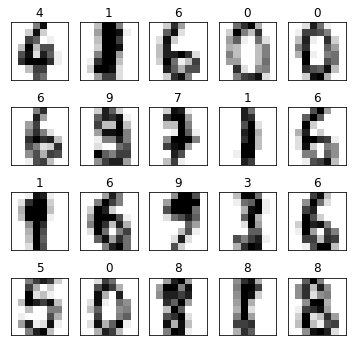

In [3]:
import numpy as np
fig, ax = plt.subplots(4, 5, figsize=(6, 6))
# centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, indx in zip(ax.flat, range(20)):
    axi.set(xticks=[], yticks=[],title=y_true[indx])
    axi.imshow(np.reshape(X[indx],(8,8)), interpolation='nearest', cmap=plt.cm.binary)

Totally we have 10 classes. Build a k-means model for classification of the digits data.

## Import Libraries



In [4]:
import numpy as np
import pandas as pd

import sklearn
from sklearn.preprocessing import scale
import sklearn.metrics as sm
from sklearn.cluster import KMeans

from sklearn import datasets
##from sklearn.datasets.samples_generator import make_blobs
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

## Apply Kmean Clustering



In [5]:
#Build model
n_clusters=10
kmeans=KMeans(n_clusters=n_clusters)
kmeans.fit(X)

#Prediction
y_kmeans = kmeans.predict(X)
print(y_kmeans)
centers=kmeans.cluster_centers_
print(y_kmeans.shape,centers.shape)


[7 8 6 ... 0 2 9]
(1797,) (10, 64)


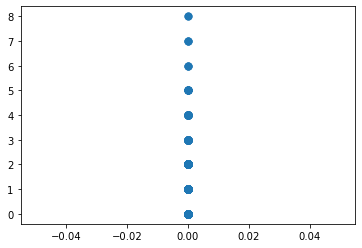

In [6]:
plt.scatter(X[:, 0], X[:, 1], s=50);

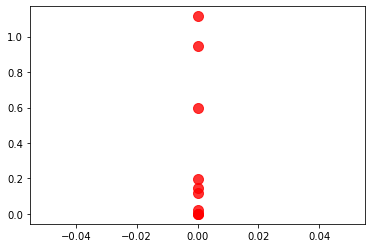

In [7]:
plt.scatter(centers[:,0],centers[:,1],c='red',s=100,alpha=0.8)

#### Plotting the clusters and corresponding centroids:

## Predictions and Evaluations



In [8]:
from scipy.stats import mode
labels = np.zeros_like(y_kmeans)
for i in range(n_clusters):
    mask=(y_kmeans==i)
    labels[mask]=mode(y_true[mask])[0]

In [9]:
print('Accuracy',accuracy_score(y_true,labels))

Accuracy 0.7929883138564274


## Visualization

Use your creativity to visualize the results (e.g. performance of the model, distribution of the data with predicted lables, etc.)

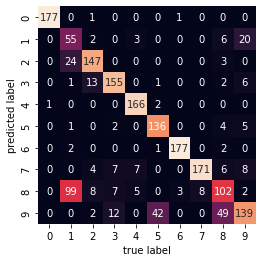

In [10]:
conf_mat = confusion_matrix(y_true, labels)
sns.heatmap(conf_mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=range(n_clusters),
            yticklabels=range(n_clusters))
plt.xlabel('true label')
plt.ylabel('predicted label');